# Rule-Based Sentiment Analysis — Philippine Educational System

Multilingual (English / Tagalog / Taglish) rule-based sentiment classifier, improved over five versions and evaluated against the group's manual labels.

**Inputs** (kept in `datasets/` locally, or uploaded to `/content/` in Colab):
| File | Needed | From |
|---|---|---|
| `final_training_data.csv` | yes | `DatasetFixes.ipynb` |
| `final_unseen_data.csv` | yes | `DatasetFixes.ipynb` |
| `final_manual_labels.csv` | yes, for metrics | manual labeling (`manual_label`: `1` positive, `0` neutral, `-1` negative) |
| `topic_assignments_train.csv`, `topic_assignments_holdout.csv` | optional, for sentiment per topic | `TopicModeling.ipynb` (`topic_modeling_outputs/`) |

**Steps:** 1 load data → 2 rules (v1 → v5) → 3 predicted class mix per version → 4 10-fold cross-validation on the labeled 90% → 5 what changed between versions → 6 final test on the unseen 10% → 7 sentiment per topic → 8 save.

**Output:** `predictions_all.csv` (one row per record: dataset, topic, manual label, score, predicted label).

## Step 1 — Load the data and the manual labels
Records with empty `text` (articles and Reddit posts that only have a title) use their **title** instead, so no records are dropped. Manual labels are matched by `record_id`; records without a label are still predicted but left out of the metrics.

In [1]:
import os, re, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, cohen_kappa_score)
warnings.filterwarnings("ignore")
try:
    from google.colab import files      # only used for the download in Step 8
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)

# Looks in datasets/ (running locally from the repo), topic_modeling_outputs/, and /content/ (Colab uploads).
# Also finds Colab-renamed copies like "final_training_data (1).csv".
DATA_DIRS = ["datasets", "topic_modeling_outputs", "/content/datasets",
             "/content/topic_modeling_outputs", "/content", "."]

def find_file(name, required=True):
    stem, ext = os.path.splitext(name)
    for d in DATA_DIRS:
        exact = os.path.join(d, name)
        if os.path.exists(exact):
            return exact
        hits = sorted(glob.glob(os.path.join(d, stem + " (*)" + ext)))
        if hits:
            return hits[-1]
    if required:
        raise FileNotFoundError(f"Upload {name} to /content/ (Colab) or keep it in datasets/ (local).")
    return None

if IN_COLAB and not find_file("final_training_data.csv", required=False):
    uploaded = files.upload()   # upload the training, unseen, label (and optional topic) files

TRAIN_FILE       = find_file("final_training_data.csv")
TEST_FILE        = find_file("final_unseen_data.csv")
LABEL_FILE       = find_file("final_manual_labels.csv", required=False)
TOPIC_TRAIN_FILE = find_file("topic_assignments_train.csv", required=False)
TOPIC_TEST_FILE  = find_file("topic_assignments_holdout.csv", required=False)
print("Training:", TRAIN_FILE, "| Unseen:", TEST_FILE, "| Labels:", LABEL_FILE)
print("Topics:  ", TOPIC_TRAIN_FILE, "|", TOPIC_TEST_FILE)

INCLUDE_ARTICLES = True
CLASSES = ["positive", "neutral", "negative"]
COLORS = {"positive": "#2e9e5b", "neutral": "#8a8f98", "negative": "#d64545"}
FINAL_VERSION = "v3_+negation+intensity"     # replaced by the best version in Step 4 when labels exist
LABEL_MAP = {"1": "positive", "1.0": "positive", "0": "neutral", "0.0": "neutral",
             "-1": "negative", "-1.0": "negative",
             "positive": "positive", "neutral": "neutral", "negative": "negative"}

labels = None
if LABEL_FILE:
    labels = pd.read_csv(LABEL_FILE)[["record_id", "manual_label"]]
    labels["label"] = labels["manual_label"].astype(str).str.strip().str.lower().map(LABEL_MAP)
    labels = labels.dropna(subset=["label"]).drop_duplicates("record_id")[["record_id", "label"]]

def load(path):
    d = pd.read_csv(path)
    has_text = d["text"].notna() & (d["text"].astype(str).str.strip() != "")
    d["text"] = d["text"].where(has_text, d["title"])        # title-only records use their title
    d = d.dropna(subset=["text"])
    d = d[d["text"].astype(str).str.strip() != ""]
    if not INCLUDE_ARTICLES and "record_type" in d.columns:
        d = d[d["record_type"] != "article"]
    d = d.merge(labels, on="record_id", how="left") if labels is not None else d.assign(label=np.nan)
    return d.reset_index(drop=True)

dev_all, test_all = load(TRAIN_FILE), load(TEST_FILE)
dev_lab, test_lab = dev_all.dropna(subset=["label"]), test_all.dropna(subset=["label"])
HAS_TRAIN_LABELS = len(dev_lab) >= 30
HAS_TEST_LABELS = len(test_lab) > 0

print(f"\nTraining rows: {len(dev_all)} ({len(dev_lab)} labeled) | Unseen rows: {len(test_all)} ({len(test_lab)} labeled)")
for name, d in (("training", dev_all), ("unseen", test_all)):
    missing = d.loc[d["label"].isna(), "record_id"].tolist()
    if missing:
        print(f"  {len(missing)} {name} records have no manual label (left out of the metrics): {missing}")

Training: datasets\final_training_data.csv | Unseen: datasets\final_unseen_data.csv | Labels: datasets\final_manual_labels.csv
Topics:   topic_modeling_outputs\topic_assignments_train.csv | topic_modeling_outputs\topic_assignments_holdout.csv

Training rows: 180 (151 labeled) | Unseen rows: 20 (0 labeled)
  29 training records have no manual label (left out of the metrics): ['data00593', 'data16037', 'data00044', 'data00101', 'data12513', 'data00358', 'data01542', 'data02286', 'data00111', 'data00260', 'data00063', 'data00613', 'data00592', 'data00630', 'data09067', 'data00033', 'data11362', 'data00342', 'data01580', 'data10978', 'data00628', 'data00235', 'data00210', 'data00633', 'data00602', 'data00596', 'data11814', 'data00166', 'data11145']
  20 unseen records have no manual label (left out of the metrics): ['data00100', 'data14704', 'data00061', 'data12822', 'data00565', 'data14402', 'data00364', 'data00233', 'data15889', 'data12279', 'data00359', 'data00017', 'data00332', 'data00

## Step 2 — The rules (five versions)
| Version | Rule change |
|---|---|
| **v1_baseline** | Small English + Tagalog word list, plain word matching |
| **v2_+lexicon+cleaning** | Expanded word list (~270 words), Tagalog affix matching (*mahirap / nahirapan → hirap*), text cleaning (emoji leftovers, *problem solving*), dropped *sana* / *mahal* |
| **v3_+negation+intensity** | Negation (*not, hindi, wala…* within 3 words flips the polarity) + intensifiers (*sobra, grabe, napaka…* ×1.5) |
| **v4_+vocabulary** | Added everyday praise / complaint words (*gift, award, respect, hopeless, inutil*) and Filipino sighs (*haist, hays*) that v3 scored as neutral |
| **v5_+contrast** | Contrast words (*but, pero, kaso, however*) halve the score of what came before, because the opinion usually follows them; hyphenated words stay whole so *never-ending* is not read as the negation *never* |

v4 and v5 came from reading the records v3 got wrong in the **training** set. The words added are general words, not phrases copied from single records, and the unseen 10% was never looked at, so the final test stays fair.

Score = sum of word polarities. Score > 0 → positive, < 0 → negative, = 0 → neutral.

In [2]:
# ---- v1 baseline word list (original, small) ----
SMALL_POS = set("""good great excellent love helpful improve better amazing best thanks thank support free proud
safe benefit progress maganda mahusay magaling salamat mabuti masaya galing tama maayos makakabuti pabor
sana mabait""".split())
SMALL_NEG = set("""bad poor terrible hate worse worst fail useless problem lack crisis corrupt expensive stress
unfair broken shortage pangit masama mahirap kulang palpak sayang hirap mali mahal pagod reklamo
kakulangan bulok""".split())

# ---- v2/v3 expanded word list ----
POS_EN = """good great excellent love loved helpful improve improved improving improvement better amazing best
thanks thank support supported proud safe benefit benefits progress success successful effective wonderful
awesome nice happy glad hope hopeful congratulations congrats recommend valuable quality decent strong
brilliant impressive agree perfect grateful appreciate appreciated deserve opportunity empower inspiring
honest handy correct excited free fair solid smart worth helpful enjoy enjoyed""".split()
NEG_EN = """bad poor terrible hate worse worst fail failed failure useless problem problems lack lacking crisis
corrupt corruption expensive stress stressful unfair broken shortage faulty sad tough struggle struggling
struggled difficult bankrupt deteriorating deteriorate poverty blame blaming limited mediocre downside
ignorant stupid dumb ridiculous shame shameful disappointing disappointed unfortunately issues suffer
suffering victim violence shooting danger dangerous unsafe worry worried angry annoying waste wasted
overpriced outdated flawed incompetent lazy sucks awful horrible pathetic toxic abuse cheating cheat scam
fake bully bullying unemployed underpaid overworked burnout inadequate insufficient neglect weak wrong
sick decline declining lowest harder""".split()
POS_TL = """maganda ganda mahusay husay magaling galing salamat pasalamat mabuti masaya saya tama maayos ayos
makakabuti pabor mabait bait matagumpay tagumpay malinaw linaw tulong bilib hanga mabuhay maasahan
pakinabang swerte sulit tuwa malasakit pagmamahal""".split()
NEG_TL = """pangit masama mahirap hirap kulang palpak sayang mali pagod reklamo kakulangan bulok magnanakaw
nakawan nakaw ninakaw tamad bobo tanga gago buwisit inis galit nakakainis nakakagalit hiya kahihiyan
kawawa pahirap pabaya kapabayaan mababa bumagsak bagsak mahina kahirapan problema suliranin trahedya
sira delikado panganib takot lungkot malungkot sakit iyak abuso korap kurakot kurapsyon kapos gutom
bumaba""".split()
BIG_POS, BIG_NEG = set(POS_EN) | set(POS_TL), set(NEG_EN) | set(NEG_TL)

# ---- v4 additions: everyday praise / complaint words and Filipino sighs found missing in v3 ----
EXTRA_POS = set("""gift cherish honor honors honored award awards awarded excellence achievement achievements respect
respected blessed blessing inspire inspired inspiration dedicated dedication thankful thankyou salute kudos""".split())
EXTRA_NEG = set("""hopeless sadly killing kill killed inappropriate shortfall delayed deadly haist hays hayst hayss
hahayy hay nakakalungkot nakakaawa kawalan inutil walanghiya""".split())

# ---- v5 additions: contrast words (the part after "but / pero" usually carries the opinion) ----
CONTRAST = {"but", "pero", "kaso", "however", "although", "though", "yet", "subalit", "ngunit"}

NEGATORS = {"not","no","never","without","hardly","barely","nothing","hindi","di","wala","walang","ayaw","hinde"}
INTENSIFIERS = {"very","so","really","extremely","super","sobra","talaga","grabe","napaka","sobrang"}
PREFIXES = ["napaka","pinaka","nakaka","magpa","nagpa","mapag","pagka","mag","nag","pag","ma","na","ka","pa"]
SUFFIXES = ["han","hin","an","in"]

def tokenize(text, clean=True):
    text = str(text).lower()
    text = re.sub(r"http\S+|@\w+", " ", text)
    if clean:
        text = re.sub(r"\bud[0-9a-f]{2,4}\b", " ", text)       # emoji escape leftovers (ud83c ...)
        text = re.sub(r"problem[- ]solving", " ", text)         # not a complaint
    return re.findall(r"[a-zñ']+", text)

def word_polarity(tok, pos, neg, stem):
    if tok in pos: return 1.0
    if tok in neg: return -1.0
    if not stem: return 0.0
    cands = set()
    for p in PREFIXES:                      # Tagalog affixes: mahirap/nahirapan -> hirap
        if tok.startswith(p) and len(tok) - len(p) >= 4:
            rest = tok[len(p):]; cands.add(rest)
            for s in SUFFIXES:
                if rest.endswith(s) and len(rest) - len(s) >= 4:
                    cands.add(rest[:-len(s)])
    for c in cands:
        if c in pos: return 1.0
        if c in neg: return -1.0
    return 0.0

class RuleBasedSentiment:
    """score > band -> positive | score < -band -> negative | otherwise -> neutral"""
    def __init__(self, big_lexicon=False, stemming=False, cleaning=False,
                 negation=False, intensifiers=False, neutral_band=0.0,
                 extra_vocab=False, contrast=False, join_hyphens=False):
        self.big, self.stem, self.clean = big_lexicon, stemming, cleaning
        self.neg_on, self.int_on, self.band = negation, intensifiers, neutral_band
        self.contrast, self.join_hyphens = contrast, join_hyphens
        self.pos, self.neg = (BIG_POS, BIG_NEG) if big_lexicon else (SMALL_POS, SMALL_NEG)
        if extra_vocab:
            self.pos, self.neg = self.pos | EXTRA_POS, self.neg | EXTRA_NEG

    def score(self, text):
        if self.join_hyphens:                       # "never-ending" is one word, not the negator "never"
            text = re.sub(r"(\w)-(\w)", r"\1\2", str(text))
        toks, total = tokenize(text, self.clean), 0.0
        for i, t in enumerate(toks):
            if self.contrast and t in CONTRAST:     # halve what came before "but / pero"
                total *= 0.5; continue
            s = word_polarity(t, self.pos, self.neg, self.stem)
            if s == 0.0: continue
            window = toks[max(0, i-3):i]
            if self.int_on and any(w in INTENSIFIERS for w in window): s *= 1.5
            if self.neg_on and any(w in NEGATORS for w in window): s *= -1
            total += s
        return total

    def label_from_score(self, sc):
        return "positive" if sc > self.band else "negative" if sc < -self.band else "neutral"
    def predict(self, X): return np.array([self.label_from_score(self.score(t)) for t in X])

VERSIONS = {
    "v1_baseline":            dict(),
    "v2_+lexicon+cleaning":   dict(big_lexicon=True, stemming=True, cleaning=True),
    "v3_+negation+intensity": dict(big_lexicon=True, stemming=True, cleaning=True,
                                   negation=True, intensifiers=True),
    "v4_+vocabulary":         dict(big_lexicon=True, stemming=True, cleaning=True,
                                   negation=True, intensifiers=True, extra_vocab=True),
    "v5_+contrast":           dict(big_lexicon=True, stemming=True, cleaning=True,
                                   negation=True, intensifiers=True, extra_vocab=True,
                                   contrast=True, join_hyphens=True),
}
RULE_CHANGE = {
    "v1_baseline":            "Baseline: original small English+Tagalog word list, plain word matching",
    "v2_+lexicon+cleaning":   "Expanded word list (~270 words), Tagalog affix matching (mahirap/nahirapan -> hirap), "
                              "text cleaning (emoji leftovers, 'problem solving'), dropped 'sana'/'mahal'",
    "v3_+negation+intensity": "Negation (3-word window flips polarity) + intensifiers (x1.5)",
    "v4_+vocabulary":         "Added everyday praise/complaint words (gift, award, respect, hopeless, inutil) "
                              "and Filipino sighs (haist, hays) that v3 missed",
    "v5_+contrast":           "Contrast words (but, pero, kaso, however) halve the score before them; "
                              "hyphenated words kept whole so 'never-ending' is not read as a negation",
}
final_clf = RuleBasedSentiment(**VERSIONS[FINAL_VERSION])

## Step 3 — Predicted class mix per version
How each version splits the records into positive / neutral / negative (no labels needed).

,Version,Dataset,n,positive %,neutral %,negative %,positive (n),neutral (n),negative (n)
0,v1_baseline,training,180,34.4,57.8,7.8,62,104,14
1,v1_baseline,unseen,20,35.0,65.0,0.0,7,13,0
2,v2_+lexicon+cleaning,training,180,38.3,42.8,18.9,69,77,34
3,v2_+lexicon+cleaning,unseen,20,35.0,55.0,10.0,7,11,2
4,v3_+negation+intensity,training,180,36.1,43.9,20.0,65,79,36
5,v3_+negation+intensity,unseen,20,45.0,45.0,10.0,9,9,2
6,v4_+vocabulary,training,180,39.4,38.9,21.7,71,70,39
7,v4_+vocabulary,unseen,20,45.0,45.0,10.0,9,9,2
8,v5_+contrast,training,180,40.0,38.3,21.7,72,69,39
9,v5_+contrast,unseen,20,45.0,45.0,10.0,9,9,2


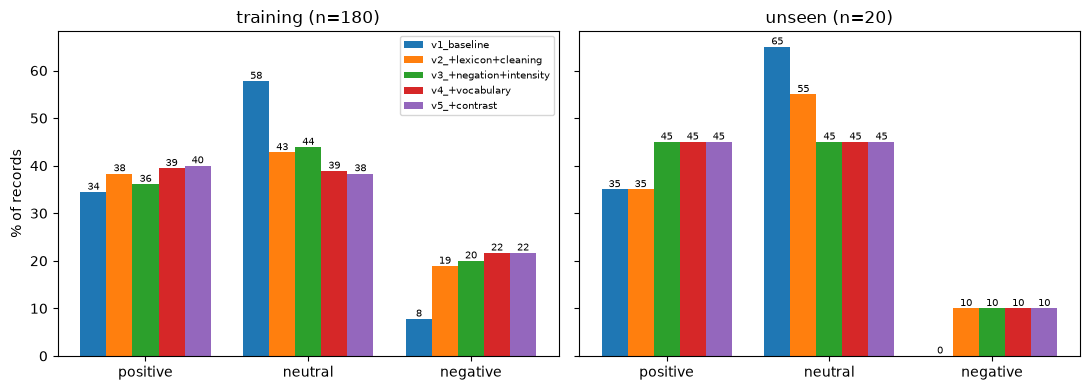

In [3]:
preds = {n: {"training": RuleBasedSentiment(**p).predict(dev_all["text"].values),
             "unseen":   RuleBasedSentiment(**p).predict(test_all["text"].values)}
         for n, p in VERSIONS.items()}

def share(arr):
    return pd.Series(arr).value_counts(normalize=True).reindex(CLASSES, fill_value=0) * 100

rows = []
for n in VERSIONS:
    for ds in ("training", "unseen"):
        s = share(preds[n][ds]); cnt = pd.Series(preds[n][ds]).value_counts().reindex(CLASSES, fill_value=0)
        rows.append({"Version": n, "Dataset": ds, "n": len(preds[n][ds]),
                     **{f"{c} %": round(s[c], 1) for c in CLASSES},
                     **{f"{c} (n)": int(cnt[c]) for c in CLASSES}})
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds in zip(axes, ("training", "unseen")):
    w, x = 0.8 / len(VERSIONS), np.arange(3)
    for k, n in enumerate(VERSIONS):
        s = share(preds[n][ds]); bars = ax.bar(x + k*w, s.values, w, label=n)
        for b in bars: ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.5, f"{b.get_height():.0f}", ha="center", fontsize=7)
    ax.set_xticks(x + w * (len(VERSIONS) - 1) / 2); ax.set_xticklabels(CLASSES); ax.set_title(f"{ds} (n={len(preds[n][ds])})")
axes[0].set_ylabel("% of records"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Step 4 — 10-fold cross-validation on the labeled training set (90%)
Each version is scored against the manual labels with stratified 10-fold cross-validation. The rule-based model has no trained parameters, so each fold measures how well the fixed rules do on a different tenth of the data; the spread across folds shows how stable the accuracy is. The version with the best mean **macro-F1** is selected for the final test.

Label distribution (labeled training records):


,records
label,
positive,56
neutral,51
negative,44



10-fold cross-validation (n = 151 labeled training records):


,Version,accuracy (mean ± SD),precision (mean ± SD),recall (mean ± SD),macro_F1 (mean ± SD)
0,v1_baseline,0.490 ± 0.123,0.454 ± 0.202,0.471 ± 0.123,0.426 ± 0.140
1,v2_+lexicon+cleaning,0.503 ± 0.128,0.488 ± 0.178,0.489 ± 0.125,0.468 ± 0.140
2,v3_+negation+intensity,0.523 ± 0.140,0.521 ± 0.180,0.510 ± 0.135,0.491 ± 0.151
3,v4_+vocabulary,0.570 ± 0.109,0.549 ± 0.162,0.553 ± 0.112,0.537 ± 0.131
4,v5_+contrast,0.589 ± 0.104,0.570 ± 0.162,0.576 ± 0.109,0.556 ± 0.129


Selected version (best mean macro-F1): v5_+contrast


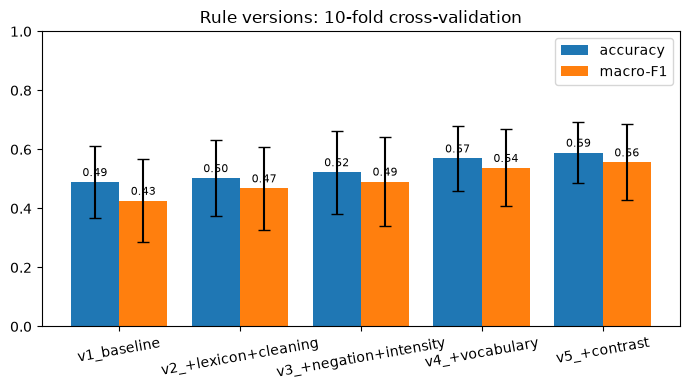


Per-fold results for v5_+contrast:


,Fold,n,accuracy,precision,recall,macro_F1
0,1,16,0.625,0.722,0.611,0.635
1,2,15,0.6,0.572,0.572,0.568
2,3,15,0.533,0.375,0.478,0.42
3,4,15,0.6,0.6,0.589,0.591
4,5,15,0.6,0.579,0.622,0.56
5,6,15,0.6,0.55,0.55,0.53
6,7,15,0.6,0.578,0.6,0.585
7,8,15,0.733,0.738,0.733,0.722
8,9,15,0.333,0.236,0.333,0.275
9,10,15,0.667,0.75,0.667,0.677


Per-class report, all 10 folds pooled (v5_+contrast):


              precision    recall  f1-score   support

    positive       0.64      0.70      0.67        56
     neutral       0.52      0.57      0.54        51
    negative       0.62      0.48      0.54        44

    accuracy                           0.59       151
   macro avg       0.59      0.58      0.58       151
weighted avg       0.59      0.59      0.59       151



,predicted positive,predicted neutral,predicted negative
actual positive,39,13,4
actual neutral,13,29,9
actual negative,9,14,21


In [4]:
def cv_scores(params, data, n_splits):
    X, y = data["text"].values, data["label"].values
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    folds, oof = [], np.empty(len(y), dtype=object)
    clf = RuleBasedSentiment(**params)
    for k, (_, va) in enumerate(skf.split(X, y), 1):
        pred = clf.predict(X[va]); oof[va] = pred
        p, r, f, _ = precision_recall_fscore_support(y[va], pred, labels=CLASSES, average="macro", zero_division=0)
        folds.append({"Fold": k, "n": len(va), "accuracy": accuracy_score(y[va], pred),
                      "precision": p, "recall": r, "macro_F1": f})
    return pd.DataFrame(folds), oof

if HAS_TRAIN_LABELS:
    n_splits = max(2, min(10, int(dev_lab["label"].value_counts().min())))
    print("Label distribution (labeled training records):")
    display(dev_lab["label"].value_counts().reindex(CLASSES).to_frame("records"))

    cv_rows, fold_tables, oof_preds = [], {}, {}
    for n, p in VERSIONS.items():
        folds, oof = cv_scores(p, dev_lab, n_splits)
        fold_tables[n], oof_preds[n] = folds, oof
        cv_rows.append({"Version": n, **{f"{m} (mean ± SD)": f"{folds[m].mean():.3f} ± {folds[m].std():.3f}"
                                         for m in ["accuracy", "precision", "recall", "macro_F1"]},
                        "_f1": folds["macro_F1"].mean(), "_acc": folds["accuracy"].mean()})
    cv_df = pd.DataFrame(cv_rows)
    print(f"\n{n_splits}-fold cross-validation (n = {len(dev_lab)} labeled training records):")
    display(cv_df.drop(columns=["_f1", "_acc"]))

    FINAL_VERSION = cv_df.loc[cv_df["_f1"].idxmax(), "Version"]
    final_clf = RuleBasedSentiment(**VERSIONS[FINAL_VERSION])
    print("Selected version (best mean macro-F1):", FINAL_VERSION)

    x = np.arange(len(cv_df))
    fig, ax = plt.subplots(figsize=(7, 4))
    for off, col, name in ((-0.2, "accuracy", "accuracy"), (0.2, "macro_F1", "macro-F1")):
        means = [fold_tables[n][col].mean() for n in cv_df["Version"]]
        sds = [fold_tables[n][col].std() for n in cv_df["Version"]]
        bars = ax.bar(x + off, means, 0.4, yerr=sds, capsize=4, label=name)
        for b in bars: ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.02, f"{b.get_height():.2f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(cv_df["Version"], rotation=10); ax.set_ylim(0, 1)
    ax.set_title("Rule versions: 10-fold cross-validation"); ax.legend(); plt.tight_layout(); plt.show()

    print(f"\nPer-fold results for {FINAL_VERSION}:")
    ft = fold_tables[FINAL_VERSION].round(3)
    display(pd.concat([ft, pd.DataFrame([{"Fold": "mean ± SD", "n": int(ft["n"].sum()),
                       **{m: f"{fold_tables[FINAL_VERSION][m].mean():.3f} ± {fold_tables[FINAL_VERSION][m].std():.3f}"
                          for m in ["accuracy", "precision", "recall", "macro_F1"]}}])], ignore_index=True))

    print(f"Per-class report, all {n_splits} folds pooled ({FINAL_VERSION}):")
    print(classification_report(dev_lab["label"], oof_preds[FINAL_VERSION], labels=CLASSES, zero_division=0))
    cm = confusion_matrix(dev_lab["label"], oof_preds[FINAL_VERSION], labels=CLASSES)
    display(pd.DataFrame(cm, index=[f"actual {c}" for c in CLASSES], columns=[f"predicted {c}" for c in CLASSES]))
else:
    final_clf = RuleBasedSentiment(**VERSIONS[FINAL_VERSION])
    print("Not enough manual labels for cross-validation; using", FINAL_VERSION)

## Step 5 — What changed between versions
Share of predictions that changed from one version to the next, agreement between consecutive versions (Cohen's kappa), and example records whose label changed.

In [5]:
names = list(VERSIONS)
all_text = np.concatenate([dev_all["text"].values, test_all["text"].values])
all_pred = {n: np.concatenate([preds[n]["training"], preds[n]["unseen"]]) for n in names}

rows, prev = [], None
for n in names:
    s = share(all_pred[n])
    row = {"Version": n, "Rule change": RULE_CHANGE[n], **{f"{c} %": round(s[c], 1) for c in CLASSES}}
    if prev is None:
        row["% predictions changed"] = "-"; row["Agreement (kappa)"] = "-"
    else:
        row["% predictions changed"] = f"{(all_pred[n] != all_pred[prev]).mean():.1%}"
        row["Agreement (kappa)"] = round(cohen_kappa_score(all_pred[prev], all_pred[n]), 3)
    rows.append(row); prev = n
display(pd.DataFrame(rows))

first, last = names[0], names[-1]
print(f"\nHow predictions moved from {first} to {last} (rows = {first}, columns = {last}):")
display(pd.crosstab(pd.Series(all_pred[first], name=first), pd.Series(all_pred[last], name=last))
        .reindex(index=CLASSES, columns=CLASSES, fill_value=0))

changed = np.where(all_pred[first] != all_pred[last])[0]
ex = pd.DataFrame({"text": [all_text[i][:110] for i in changed],
                   first: all_pred[first][changed], last: all_pred[last][changed]})
print(f"\nExamples of rows whose label changed ({len(changed)} in total) - check whether the change is an improvement:")
display(ex.head(15))

,Version,Rule change,positive %,neutral %,negative %,% predictions changed,Agreement (kappa)
0,v1_baseline,"Baseline: original small English+Tagalog word list, plain word matching",34.5,58.5,7.0,-,-
1,v2_+lexicon+cleaning,"Expanded word list (~270 words), Tagalog affix matching (mahirap/nahirapan -> hirap), text clean...",38.0,44.0,18.0,25.5%,0.574
2,v3_+negation+intensity,Negation (3-word window flips polarity) + intensifiers (x1.5),37.0,44.0,19.0,5.0%,0.921
3,v4_+vocabulary,"Added everyday praise/complaint words (gift, award, respect, hopeless, inutil) and Filipino sigh...",40.0,39.5,20.5,7.0%,0.89
4,v5_+contrast,"Contrast words (but, pero, kaso, however) halve the score before them; hyphenated words kept who...",40.5,39.0,20.5,3.5%,0.945



How predictions moved from v1_baseline to v5_+contrast (rows = v1_baseline, columns = v5_+contrast):


v5_+contrast,positive,neutral,negative
v1_baseline,,,
positive,54,4,11
neutral,25,72,20
negative,2,2,10



Examples of rows whose label changed (64 in total) - check whether the change is an improvement:


,text,v1_baseline,v5_+contrast
0,dito na nagkakamali ang karamihan sa mga teachers natin hindi pwedeng mabait lang ang bata kaila...,positive,negative
1,that teacher is a gift from god he has a purpose in life by providing education to the less fort...,neutral,positive
2,i remember my aunt telling me a story about how when my mom got into a state university in a maj...,neutral,positive
3,i think people are being overly critical in his statement my point naman siya may mga matatalino...,positive,neutral
4,sayang ka gagraduate lang ng anak ko sa sti multi media arts unifast grantee pero at the end of ...,negative,neutral
5,we already had essay-type questions back when i was in grade i remember struggling a lot with th...,neutral,negative
6,sa tawi tawi ma develop sana,positive,neutral
7,education secretary sonny angara is urging congress to restore funding for the government s lear...,positive,negative
8,catholic education authorities are calling for the immediate release of delayed government vouch...,neutral,positive
9,prc honors ceu dean with eric c nubla excellence award manila philippines dr maria rita dacanay-...,neutral,positive


## Step 6 — Final test on the unseen data (10%)
The selected version is run **once** on the held-out 10%. With manual labels this gives the final accuracy, precision, recall, F1, and confusion matrix; without them, only the predicted class mix can be compared with the training set.

In [6]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    fig, ax = plt.subplots(figsize=(5, 4.2))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual (manual label)"); ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.colorbar(im); plt.tight_layout(); plt.show()

for d in (dev_all, test_all):
    d["sentiment_score"] = [final_clf.score(t) for t in d["text"]]
    d["predicted_label"] = [final_clf.label_from_score(s) for s in d["sentiment_score"]]

if HAS_TEST_LABELS:
    t = test_all.dropna(subset=["label"])
    p, r, f, _ = precision_recall_fscore_support(t["label"], t["predicted_label"], labels=CLASSES,
                                                 average="macro", zero_division=0)
    print(f"UNSEEN results for {FINAL_VERSION} (n = {len(t)} labeled records)")
    display(pd.DataFrame([{"accuracy": round(accuracy_score(t["label"], t["predicted_label"]), 3),
                           "precision (macro)": round(p, 3), "recall (macro)": round(r, 3),
                           "F1 (macro)": round(f, 3)}]))
    print(classification_report(t["label"], t["predicted_label"], labels=CLASSES, zero_division=0))
    plot_confusion(t["label"], t["predicted_label"], f"Confusion matrix — unseen ({FINAL_VERSION})")
    if len(t) < len(test_all):
        print(f"Note: {len(test_all) - len(t)} unseen records have no manual label and are not scored.")
else:
    print("The unseen records have no manual labels yet, so the final test cannot be scored.")
    print("Label them (records_to_label.csv from DatasetFixes.ipynb), add them to final_manual_labels.csv, and re-run.\n")

# Prediction behavior on training vs unseen (useful with or without labels)
share = lambda arr: pd.Series(arr).value_counts(normalize=True).reindex(CLASSES, fill_value=0) * 100
tr_s, un_s = share(dev_all["predicted_label"]), share(test_all["predicted_label"])
display(pd.DataFrame({"training %": tr_s.round(1), "unseen %": un_s.round(1),
                      "difference (unseen - training)": (un_s - tr_s).round(1)}))
try:
    from scipy.stats import chi2_contingency
    table = np.array([[(d["predicted_label"] == c).sum() for c in CLASSES] for d in (dev_all, test_all)])
    pval = chi2_contingency(table)[1]
    print(f"Chi-square test of equal predicted sentiment mix: p = {pval:.3f}",
          "(no significant difference)" if pval > 0.05 else "(the mix differs significantly)")
except Exception as e:
    print("Chi-square test skipped:", e)
print(f"Caution: the unseen set has only {len(test_all)} rows, so small differences are noise.")

The unseen records have no manual labels yet, so the final test cannot be scored.
Label them (records_to_label.csv from DatasetFixes.ipynb), add them to final_manual_labels.csv, and re-run.



,training %,unseen %,difference (unseen - training)
predicted_label,,,
positive,40.0,45.0,5.0
neutral,38.3,45.0,6.7
negative,21.7,10.0,-11.7


Chi-square test of equal predicted sentiment mix: p = 0.470 (no significant difference)
Caution: the unseen set has only 20 rows, so small differences are noise.


## Step 7 — Sentiment per topic
Uses the **LDA topics from `TopicModeling.ipynb`** (`topic_assignments_train.csv` and `topic_assignments_holdout.csv`, column `lda_topic_label`), so the topics match the topic modeling section of the paper. Records the topic model skipped (too few words) are shown as *Unassigned*. If the topic files are missing, a simple NMF model is fitted instead as a placeholder — re-run after `TopicModeling.ipynb` for the final results.

Using LDA topics from: topic_modeling_outputs\topic_assignments_train.csv, topic_modeling_outputs\topic_assignments_holdout.csv

Counts per topic:


predicted_label,positive,neutral,negative,total
topic,,,,
"Classroom learning, grades & DepEd programs",16,13,5,34
Critical thinking & global competitiveness,15,15,7,37
Curriculum relevance & work readiness,11,13,7,31
PISA results & language of instruction,11,8,7,26
Public school quality & teaching problems,21,10,15,46
Unassigned,7,19,0,26


Share (%) per topic:


predicted_label,positive,neutral,negative
topic,,,
"Classroom learning, grades & DepEd programs",47.1,38.2,14.7
Critical thinking & global competitiveness,40.5,40.5,18.9
Curriculum relevance & work readiness,35.5,41.9,22.6
PISA results & language of instruction,42.3,30.8,26.9
Public school quality & teaching problems,45.7,21.7,32.6
Unassigned,26.9,73.1,0.0


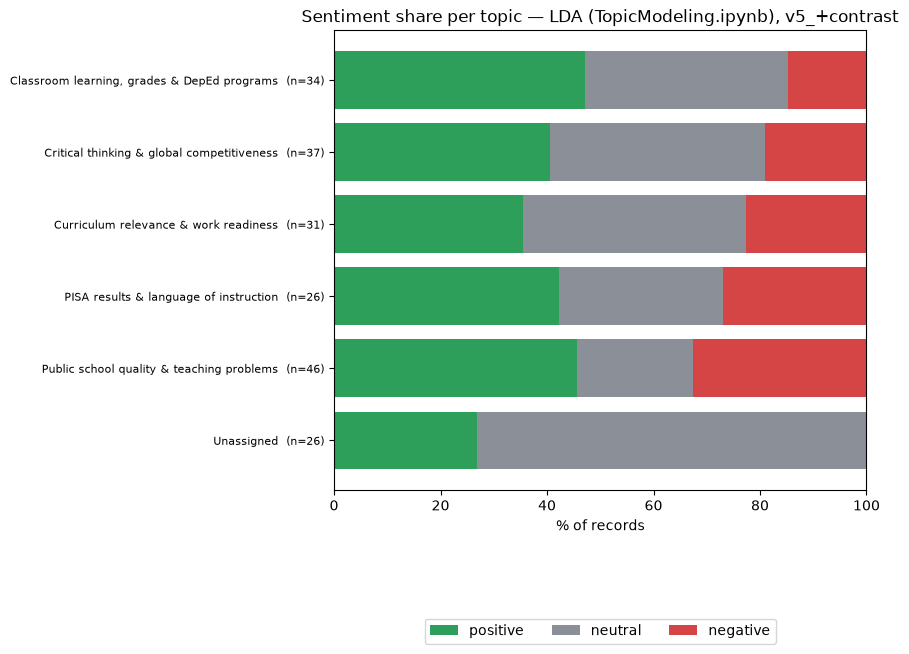

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF

all_df = pd.concat([dev_all.assign(dataset="training"), test_all.assign(dataset="unseen")], ignore_index=True)

def read_topics(path):
    tp = pd.read_csv(path)
    col = "lda_topic_label" if "lda_topic_label" in tp.columns else "topic"
    return tp[["record_id", col]].rename(columns={col: "topic"})

topic_paths = [p for p in (TOPIC_TRAIN_FILE, TOPIC_TEST_FILE) if p]
if topic_paths:
    tp = pd.concat([read_topics(p) for p in topic_paths]).drop_duplicates("record_id")
    all_df = all_df.merge(tp, on="record_id", how="left")
    all_df["topic"] = all_df["topic"].fillna("Unassigned").astype(str)
    TOPIC_SOURCE = "LDA (TopicModeling.ipynb)"
    print("Using LDA topics from:", ", ".join(topic_paths))
    if not TOPIC_TEST_FILE:
        print("Note: topic_assignments_holdout.csv not found, so unseen records are 'Unassigned'.")
else:
    N_TOPICS = 5
    TOPIC_SOURCE = f"NMF placeholder ({N_TOPICS} topics)"
    print(f"No topic assignment files found, so fitting a placeholder NMF model with {N_TOPICS} topics.\n"
          "Run TopicModeling.ipynb and put topic_assignments_train.csv / topic_assignments_holdout.csv "
          "next to the datasets, then re-run this step.")
    TL_STOP = set("""ang ng sa na mga ay at ko mo po ito yung nang para pero kung naman lang din rin ba ni si kay nito
    niya sila kami tayo namin natin kayo ninyo iyan iyon yan ung nga pa opo wala may meron dahil kasi pag mag
    glance filipino philippines deped""".split())
    def topic_text(t):
        t = re.sub(r"http\S+|@\w+", " ", str(t).lower())
        return re.sub(r"\bud[0-9a-f]{2,4}\b", " ", t)
    vec = TfidfVectorizer(preprocessor=topic_text, token_pattern=r"\b[a-zñ]{3,}\b",
                          stop_words=list(ENGLISH_STOP_WORDS | TL_STOP), max_df=0.8, min_df=2)
    X_train = vec.fit_transform(dev_all["text"])
    nmf = NMF(n_components=N_TOPICS, init="nndsvda", random_state=42, max_iter=500).fit(X_train)
    W = nmf.transform(vec.transform(all_df["text"]))
    vocab = np.array(vec.get_feature_names_out())
    tnames = [f"T{k+1}: " + ", ".join(vocab[np.argsort(nmf.components_[k])[::-1][:4]]) for k in range(N_TOPICS)]
    all_df["topic"] = [tnames[i] if W[j].sum() > 0 else "Unassigned" for j, i in enumerate(W.argmax(axis=1))]

ct = pd.crosstab(all_df["topic"], all_df["predicted_label"]).reindex(columns=CLASSES, fill_value=0)
ct["total"] = ct.sum(axis=1)
pct = (ct[CLASSES].div(ct["total"], axis=0) * 100).round(1)
print("\nCounts per topic:");  display(ct)
print("Share (%) per topic:"); display(pct)

fig, ax = plt.subplots(figsize=(9, 0.9*len(pct) + 1.5))
left = np.zeros(len(pct))
for c in CLASSES:
    ax.barh(range(len(pct)), pct[c], left=left, color=COLORS[c], label=c); left += pct[c].values
ax.set_yticks(range(len(pct))); ax.set_yticklabels([f"{t}  (n={ct.loc[t,'total']})" for t in pct.index], fontsize=8)
ax.set_xlabel("% of records"); ax.set_title(f"Sentiment share per topic — {TOPIC_SOURCE}, {FINAL_VERSION}")
ax.invert_yaxis(); ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.35))
plt.tight_layout(); plt.show()

## Step 8 — Save the predictions

In [8]:
keep = [c for c in ["record_id", "platform", "record_type", "detected_language", "dataset", "topic",
                    "text", "label", "sentiment_score", "predicted_label"] if c in all_df.columns]
all_df[keep].rename(columns={"label": "manual_label"}).to_csv("predictions_all.csv", index=False)
print(f"Saved predictions_all.csv with {len(all_df)} rows (version: {FINAL_VERSION}, topics: {TOPIC_SOURCE})")
if IN_COLAB:
    files.download("predictions_all.csv")

Saved predictions_all.csv with 200 rows (version: v5_+contrast, topics: LDA (TopicModeling.ipynb))
